# Examen Segundo Corte

**Matemáticas para Inteligencia Artificial**  
Maestría en Inteligencia Artificial  
Universidad Politécnica Metropolitana de Hidalgo

**Integrantes:** Luis David Gonzalez Romero  
Diego Alberto Ortega Carreto  
**Docente:** Dr. Francisco Rafael Trejo Macotela  
**Fecha:** 6 de noviembre de 2026

In [ ]:
import platform
import random

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.precision", 8)
pd.set_option("display.max_columns", 20)


def symbolic_derivatives(expression, variables):
    return [sp.diff(expression, variable) for variable in variables]


def assert_close(actual, expected, *, rtol=1e-9, atol=1e-12):
    actual_array = np.asarray(actual, dtype=float)
    expected_array = np.asarray(expected, dtype=float)
    if not np.allclose(actual_array, expected_array, rtol=rtol, atol=atol):
        raise AssertionError(f"Diferencia mayor que la tolerancia: {actual_array} != {expected_array}")
    return True


def results_table(rows, columns):
    table = pd.DataFrame(rows, columns=columns)
    display(table)
    return table


def save_figure(fig, filename, *, dpi=180):
    fig.savefig(filename, dpi=dpi, bbox_inches="tight")
    return filename


def format_vector(vector, digits=8):
    return np.array2string(np.asarray(vector, dtype=float), precision=digits, suppress_small=False)

print(f"Python {platform.python_version()} | NumPy {np.__version__} | SymPy {sp.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.11.16 | NumPy 2.4.6 | SymPy 1.14.0 | pandas 3.0.5 | Matplotlib 3.11.2


## Parte I. Conceptos fundamentales

### I.1 Gradiente y curvas de nivel

**Pregunta.** ¿Qué relación hay entre el gradiente, las curvas de nivel y la derivada direccional?

**Respuesta.** Si una curva de nivel se parametriza como $\gamma(t)$ y pasa por $P$, entonces $f(\gamma(t))$ es constante. Por la regla de la cadena, $\nabla f(P)\cdot\gamma'(t)=0$; el gradiente es normal a la curva si no es nulo. Para cualquier vector unitario $u$, $D_uf(P)=\nabla f(P)\cdot u\leq\|\nabla f(P)\|$. La igualdad se alcanza en la dirección del gradiente; el máximo decrecimiento ocurre en la dirección opuesta.

Para ilustrarlo usamos $g(x,y)=x^2+2y^2$ en $P=(1,1)$. Es un ejemplo geométrico, no una función adicional del examen. El gradiente $(2,4)$ es ortogonal a la dirección tangente $(-4,2)$.

### I.2 Punto crítico y Hessiana

**Pregunta.** ¿Qué permite concluir la Hessiana sobre un punto crítico y qué cambia si la función es convexa?

**Respuesta.** La condición $\nabla f(z^*)=0$ elimina la variación de primer orden, pero no determina por sí sola el tipo de punto. En un punto crítico, una Hessiana definida positiva indica mínimo local estricto; una definida negativa, máximo local estricto; y una indefinida, punto silla. Si es semidefinida, la prueba no decide por sí sola. Si $f$ es convexa en un dominio convexo, todo punto crítico es mínimo global.

### I.3 SVM y Ridge

**Pregunta.** ¿Cómo se expresan la SVM de margen suave y Ridge como problemas cuadráticos, y qué efecto tiene la regularización de Ridge?

**Respuesta.** La SVM estándar de margen suave minimiza $\frac12\|w\|^2+C\sum_i\xi_i$ sujeto a restricciones lineales de margen y $\xi_i\geq0$. Ridge minimiza $\|Xw-y\|^2+\lambda\|w\|^2$, también expresable como un problema cuadrático. En las ecuaciones normales, $\lambda I$ penaliza la magnitud de los coeficientes y puede mejorar el condicionamiento de $X^TX+\lambda I$.

### I.4 Condicionamiento, estabilidad y errores

**Pregunta.** ¿En qué se distinguen el condicionamiento y la estabilidad, y cómo se diferencian los errores de truncamiento y redondeo?

**Respuesta.** El condicionamiento mide la sensibilidad del problema ante perturbaciones en los datos; la estabilidad mide el error que introduce el algoritmo al resolverlo. Aproximar $e^x$ con un polinomio de Taylor finito produce error de truncamiento. Representar $1/3$ con una cantidad finita de cifras decimales produce error de redondeo.

### I.5 Métodos de descenso y Adam

**Pregunta.** ¿Cómo se diferencian batch, SGD y minibatch, y qué papel tienen la tasa de aprendizaje y Adam?

**Respuesta.** Batch calcula cada actualización con todos los ejemplos: el paso es más costoso, pero el gradiente tiene menos ruido. SGD usa un ejemplo por paso: cada actualización cuesta menos, pero tiene mayor variabilidad. Minibatch usa un subconjunto y equilibra ambos aspectos. Reducir la tasa de aprendizaje puede amortiguar oscilaciones cerca de un punto estacionario, pero no garantiza convergencia global. Adam combina promedios móviles del gradiente y de su cuadrado, con corrección de sesgo en su formulación usual.

Figura generada: I1_gradiente_curva_nivel.png


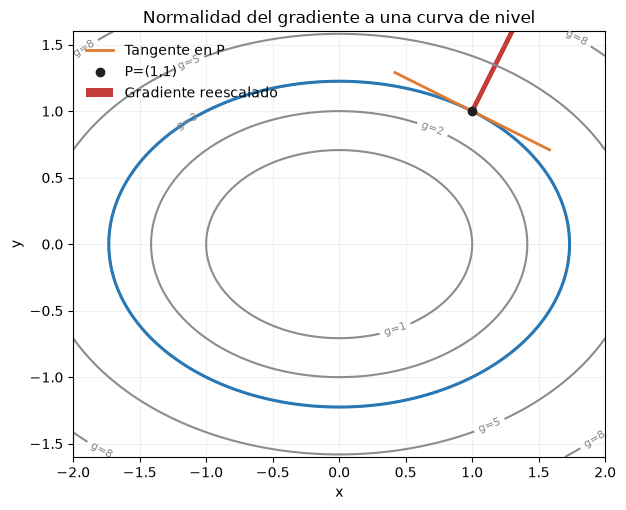

Producto punto gradiente-tangente unitario: 0


In [ ]:
illustrative_point = np.array([1.0, 1.0])
illustrative_gradient = np.array([2.0, 4.0])
tangent_direction = np.array([-4.0, 2.0]) / np.sqrt(20.0)
parameter = np.linspace(-0.65, 0.65, 100)
tangent = illustrative_point[:, None] + tangent_direction[:, None] * parameter

x_values = np.linspace(-2.0, 2.0, 300)
y_values = np.linspace(-1.6, 1.6, 300)
X_grid, Y_grid = np.meshgrid(x_values, y_values)
G_grid = X_grid**2 + 2 * Y_grid**2

fig, ax = plt.subplots(figsize=(7, 5.2))
contours = ax.contour(X_grid, Y_grid, G_grid, levels=[1, 2, 3, 5, 8], colors="0.55")
ax.clabel(contours, inline=True, fontsize=8, fmt="g=%.0f")
ax.contour(X_grid, Y_grid, G_grid, levels=[3], colors="#2878B5", linewidths=2.2)
ax.plot(tangent[0], tangent[1], color="#E07A2D", linewidth=2, label="Tangente en P")
ax.scatter(*illustrative_point, color="#202020", zorder=5, label="P=(1,1)")
ax.quiver(*illustrative_point, *(0.22 * illustrative_gradient), angles="xy", scale_units="xy", scale=1, color="#C43C39", width=0.009, label="Gradiente reescalado")
ax.set(xlabel="x", ylabel="y", title="Normalidad del gradiente a una curva de nivel")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", frameon=False)
ax.grid(alpha=0.18)
fig.tight_layout()
save_figure(fig, "I1_gradiente_curva_nivel.png")
plt.show()
plt.close(fig)

print(f"Producto punto gradiente-tangente unitario: {illustrative_gradient @ tangent_direction:.3g}")
assert abs(illustrative_gradient @ tangent_direction) < 1e-12

## Parte II. Diferenciación, jacobiana y retropropagación

### II.A Gradiente, derivada direccional y linealización

Para $f(x,y)=x^2y+\ln(1+x^2+y^2)$, las derivadas son
\[
f_x=2xy+\frac{2x}{1+x^2+y^2},\qquad
f_y=x^2+\frac{2y}{1+x^2+y^2}.
\]
En $P=(1,0)$ obtenemos $f(P)=\ln 2$ y $\nabla f(P)=(1,1)$. Con $v=(3,4)$, el unitario es $u=(3/5,4/5)$ y $D_uf(P)=7/5$. La rapidez máxima es $\sqrt{2}$ y se alcanza en $(1/\sqrt{2},1/\sqrt{2})$. La linealización es $L(x,y)=\ln 2+(x-1)+y$.

### II.B Jacobiana y aproximación lineal vectorial

Para $F(x,y)=(x^2+y,\sin x+xy)$,
\[
JF(x,y)=\begin{pmatrix}2x&1\\\cos x+y&x\end{pmatrix},\qquad
JF(0,2)=\begin{pmatrix}0&1\\3&0\end{pmatrix}.
\]
Usamos $F_{\rm lin}(S)=F(R)+JF(R)(S-R)$ con $R=(0,2)$ y $S=(0.1,1.9)$.

### II.C Retropropagación en una neurona escalar

Aplicamos la regla de la cadena a $u=wx+b$, $a=\tanh(u)$ y $\mathcal{L}=\frac12(a-y)^2$. Con los valores del examen, calculamos el pase hacia adelante, los gradientes respecto de $w$ y $b$, una actualización con $\alpha=0.1$ y la nueva pérdida. La comprobación numérica usa diferencias finitas centrales con paso $h=10^{-6}$.

In [ ]:
x, y = sp.symbols("x y", real=True)
f_expr = x**2 * y + sp.log(1 + x**2 + y**2)
grad_f_expr = symbolic_derivatives(f_expr, (x, y))
P = {x: 1, y: 0}
Q = {x: sp.Rational(105, 100), y: sp.Rational(2, 100)}
P_array = np.array([1.0, 0.0])
Q_array = np.array([1.05, 0.02])
v = np.array([3.0, 4.0])
u = v / np.linalg.norm(v)

f_P_exact = sp.simplify(f_expr.subs(P))
grad_P_exact = sp.Matrix([entry.subs(P) for entry in grad_f_expr])
L_expr = sp.simplify(f_P_exact + sum(grad_f_expr[i].subs(P) * ((x, y)[i] - (1, 0)[i]) for i in range(2)))
f_Q_exact = sp.N(f_expr.subs(Q), 16)
L_Q_exact = sp.simplify(L_expr.subs(Q))
absolute_error_Q = sp.N(abs(f_Q_exact - L_Q_exact), 12)

assert f_P_exact == sp.log(2)
assert grad_P_exact == sp.Matrix([1, 1])
assert np.isclose(np.dot(u, np.array([1.0, 1.0])), 7 / 5, rtol=0, atol=1e-15)
assert sp.simplify(L_expr - (sp.log(2) + x - 1 + y)) == 0

rows_IIA = [
    ("f(P)", str(f_P_exact), float(f_P_exact)),
    ("gradiente en P", str(grad_P_exact), format_vector(np.array(grad_P_exact, dtype=float))),
    ("D_u f(P)", "7/5", float(grad_P_exact.dot(sp.Matrix([sp.Rational(3, 5), sp.Rational(4, 5)])))),
    ("rapidez máxima", "sqrt(2)", float(sp.sqrt(2))),
    ("L(Q)", str(L_Q_exact), float(L_Q_exact)),
    ("f(Q)", str(sp.simplify(f_expr.subs(Q))), float(f_Q_exact)),
    ("error absoluto", "|f(Q)-L(Q)|", float(absolute_error_Q)),
]
results_table(rows_IIA, ["Cantidad", "Forma exacta", "Valor numérico"])
print(f"u={format_vector(u)}; dirección de máximo crecimiento={format_vector(np.array([1, 1]) / np.sqrt(2))}")

,Cantidad,Forma exacta,Valor numérico
0,f(P),log(2),0.69314718
1,gradiente en P,"Matrix([[1], [1]])",[[1.]\n [1.]]
2,D_u f(P),7/5,1.4
3,rapidez máxima,sqrt(2),1.41421356
4,L(Q),7/100 + log(2),0.76314718
5,f(Q),441/20000 + log(21029/10000),0.76536734
6,error absoluto,|f(Q)-L(Q)|,0.00222016


u=[0.6 0.8]; dirección de máximo crecimiento=[0.70710678 0.70710678]


Figura generada: IIA_curvas_gradiente_linealizacion.png


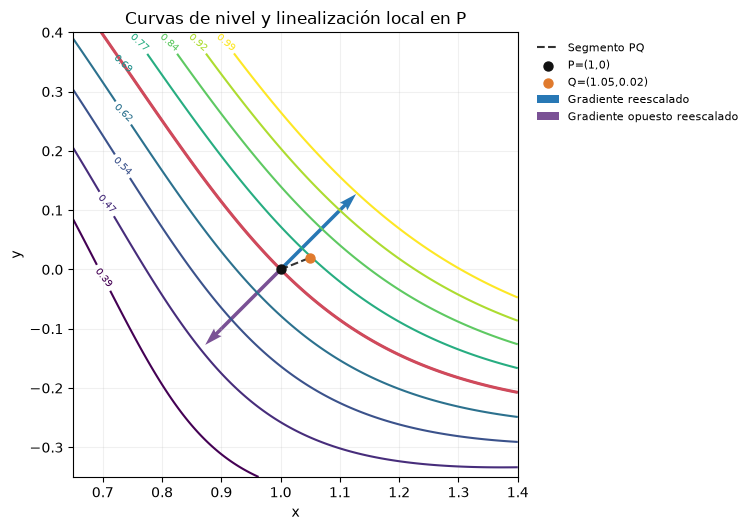

gradiente punto tangente=0.0; derivada en dirección PQ=1.29986737
Las flechas del gradiente se escalaron por 0.127279 solo para visualización.


In [ ]:
f_numeric = sp.lambdify((x, y), f_expr, modules="numpy")
x_values = np.linspace(0.65, 1.4, 260)
y_values = np.linspace(-0.35, 0.4, 260)
X_grid, Y_grid = np.meshgrid(x_values, y_values)
F_grid = f_numeric(X_grid, Y_grid)
level_at_P = float(f_P_exact)
levels = np.linspace(level_at_P - 0.3, level_at_P + 0.3, 9)

fig, ax = plt.subplots(figsize=(8.3, 5.4))
contours = ax.contour(X_grid, Y_grid, F_grid, levels=levels, cmap="viridis")
ax.clabel(contours, inline=True, fontsize=7, fmt="%.2f")
ax.contour(X_grid, Y_grid, F_grid, levels=[level_at_P], colors="#D1495B", linewidths=2.2)
ax.plot([P_array[0], Q_array[0]], [P_array[1], Q_array[1]], color="#333333", linestyle="--", linewidth=1.5, label="Segmento PQ")
ax.scatter(*P_array, color="#111111", s=42, zorder=5, label="P=(1,0)")
ax.scatter(*Q_array, color="#E07A2D", s=42, zorder=5, label="Q=(1.05,0.02)")
arrow_scale = 0.18 / np.linalg.norm(np.array(grad_P_exact, dtype=float))
gradient_at_P = np.array(grad_P_exact, dtype=float).reshape(2)
ax.quiver(*P_array, *(arrow_scale * gradient_at_P), angles="xy", scale_units="xy", scale=1, color="#2878B5", width=0.008, label="Gradiente reescalado")
ax.quiver(*P_array, *(-arrow_scale * gradient_at_P), angles="xy", scale_units="xy", scale=1, color="#7A5195", width=0.008, label="Gradiente opuesto reescalado")
ax.set(xlabel="x", ylabel="y", title="Curvas de nivel y linealización local en P")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, frameon=False)
ax.grid(alpha=0.18)
fig.tight_layout(rect=(0, 0, 0.74, 1))
save_figure(fig, "IIA_curvas_gradiente_linealizacion.png")
plt.show()
plt.close(fig)

tangent_at_P = np.array([-1.0, 1.0])
segment_direction = (Q_array - P_array) / np.linalg.norm(Q_array - P_array)
assert np.isclose(gradient_at_P @ tangent_at_P, 0.0, atol=1e-12)
assert gradient_at_P @ segment_direction > 0
print(f"gradiente punto tangente={gradient_at_P @ tangent_at_P:.1f}; derivada en dirección PQ={gradient_at_P @ segment_direction:.8f}")
print("Las flechas del gradiente se escalaron por", f"{arrow_scale:.6f}", "solo para visualización.")

In [ ]:
F_expr = sp.Matrix([x**2 + y, sp.sin(x) + x * y])
J_F_expr = F_expr.jacobian((x, y))
R = {x: 0, y: 2}
S = {x: sp.Rational(1, 10), y: sp.Rational(19, 10)}
F_R_exact = F_expr.subs(R)
J_R_exact = J_F_expr.subs(R)
delta_RS_exact = sp.Matrix([S[x] - R[x], S[y] - R[y]])
F_S_exact = F_expr.subs(S)
F_S_linear = sp.simplify(F_R_exact + J_R_exact * delta_RS_exact)
error_F = sp.simplify(F_S_exact - F_S_linear)

assert J_R_exact == sp.Matrix([[0, 1], [3, 0]])
assert F_S_linear == sp.Matrix([sp.Rational(19, 10), sp.Rational(3, 10)])
assert_close(np.array(F_S_linear, dtype=float).reshape(2), [1.9, 0.3])

print("J_F(x,y) =")
display(J_F_expr)
print("J_F(R) =")
display(J_R_exact)
print("F(S) exacto =")
display(F_S_exact)
print("F_lin(S) =")
display(F_S_linear)
print("Vector de error F(S)-F_lin(S) =")
display(error_F)
print("Valores numéricos:", format_vector(np.array(F_S_exact, dtype=float).reshape(2)), format_vector(np.array(error_F, dtype=float).reshape(2)))

J_F(x,y) =


Matrix([
[       2*x, 1],
[y + cos(x), x]])

J_F(R) =


Matrix([
[0, 1],
[3, 0]])

F(S) exacto =


Matrix([
[           191/100],
[sin(1/10) + 19/100]])

F_lin(S) =


Matrix([
[19/10],
[ 3/10]])

Vector de error F(S)-F_lin(S) =


Matrix([
[              1/100],
[-11/100 + sin(1/10)]])

Valores numéricos: [1.91       0.28983342] [ 0.01       -0.01016658]


In [ ]:
x_sym, w_sym, b_sym, y_sym, a_var = sp.symbols("x w b y a", real=True)
u_sym = w_sym * x_sym + b_sym
a_sym = sp.tanh(u_sym)
loss_as_activation = sp.Rational(1, 2) * (a_var - y_sym) ** 2
loss_sym = sp.Rational(1, 2) * (a_sym - y_sym) ** 2
dL_da_sym = sp.diff(loss_as_activation, a_var)
dL_du_sym = sp.simplify((a_sym - y_sym) * (1 - a_sym**2))
symbolic_gradients = [dL_da_sym, dL_du_sym, dL_du_sym * x_sym, dL_du_sym]

x_value, w_value, b_value, y_value, alpha = 2.0, 0.5, -1.0, 0.5, 0.1
u_value = w_value * x_value + b_value
a_value = float(np.tanh(u_value))
loss_value = 0.5 * (a_value - y_value) ** 2
grad_loss_a = a_value - y_value
grad_a_u = 1.0 - a_value**2
grad_loss_u = grad_loss_a * grad_a_u
grad_loss_w = grad_loss_u * x_value
grad_loss_b = grad_loss_u

w_updated = w_value - alpha * grad_loss_w
b_updated = b_value - alpha * grad_loss_b
u_updated = w_updated * x_value + b_updated
a_updated = float(np.tanh(u_updated))
loss_updated = 0.5 * (a_updated - y_value) ** 2

finite_difference_step = 1e-6

def scalar_loss(weight, bias):
    activation = np.tanh(weight * x_value + bias)
    return 0.5 * (activation - y_value) ** 2

finite_grad_w = (scalar_loss(w_value + finite_difference_step, b_value) - scalar_loss(w_value - finite_difference_step, b_value)) / (2 * finite_difference_step)
finite_grad_b = (scalar_loss(w_value, b_value + finite_difference_step) - scalar_loss(w_value, b_value - finite_difference_step)) / (2 * finite_difference_step)

assert (u_value, a_value, loss_value) == (0.0, 0.0, 0.125)
assert_close([grad_loss_a, grad_loss_u, grad_loss_w, grad_loss_b], [-0.5, -0.5, -1.0, -0.5])
assert_close([finite_grad_w, finite_grad_b], [grad_loss_w, grad_loss_b], atol=1e-9)

rows_IIC = [
    ("u, a, pérdida inicial", f"{u_value:.8f}, {a_value:.8f}, {loss_value:.8f}"),
    ("dL/da; da/du", f"{grad_loss_a:.8f}; {grad_a_u:.8f}"),
    ("dL/du; dL/dw; dL/db", f"{grad_loss_u:.8f}; {grad_loss_w:.8f}; {grad_loss_b:.8f}"),
    ("diferencias finitas centrales", f"{finite_grad_w:.8f}; {finite_grad_b:.8f}"),
    ("w nuevo; b nuevo", f"{w_updated:.8f}; {b_updated:.8f}"),
    ("pérdida nueva", f"{loss_updated:.8f}"),
]
results_table(rows_IIC, ["Cantidad", "Valor"])
print("Gradientes simbólicos en orden dL/da, dL/du, dL/dw, dL/db:")
for expression in symbolic_gradients:
    display(expression)
print("Derivada tanh en u=5 y u=10:", 1 - np.tanh(5.0) ** 2, 1 - np.tanh(10.0) ** 2)

,Cantidad,Valor
0,"u, a, pérdida inicial","0.00000000, 0.00000000, 0.12500000"
1,dL/da; da/du,-0.50000000; 1.00000000
2,dL/du; dL/dw; dL/db,-0.50000000; -1.00000000; -0.50000000
3,diferencias finitas centrales,-1.00000000; -0.50000000
4,w nuevo; b nuevo,0.60000000; -0.95000000
5,pérdida nueva,0.03253324


Gradientes simbólicos en orden dL/da, dL/du, dL/dw, dL/db:


a - y

(y - tanh(b + w*x))*(tanh(b + w*x)**2 - 1)

x*(y - tanh(b + w*x))*(tanh(b + w*x)**2 - 1)

(y - tanh(b + w*x))*(tanh(b + w*x)**2 - 1)

Derivada tanh en u=5 y u=10: 0.0001815832309438603 8.244614546626394e-09


## Parte III. Optimización sin restricciones

La función objetivo se escribe como
\[
f(x,y)=(x-1)^2+4(y+1)^2-4.
\]
Así, $z^*=(1,-1)$ y $f(z^*)=-4$. Su gradiente es $(2x-2,8y+8)$ y su Hessiana constante es $H=\operatorname{diag}(2,8)$. Como ambos autovalores son positivos, $f$ es estrictamente convexa y el mínimo es global y único; además, $\kappa_2(H)=8/2=4$.

Con $z_0=(3,1)$ y $\alpha=0.1$, se obtiene $z_1=(2.6,-0.6)$ y $z_2=(2.28,-0.92)$, con $f(z_0)=16$, $f(z_1)=-0.8$ y $f(z_2)=-2.336$.

El error por coordenadas satisface $e_{x,k+1}=(1-2\alpha)e_{x,k}$ y $e_{y,k+1}=(1-8\alpha)e_{y,k}$. La convergencia exige $0<\alpha<0.25$. Para $\alpha=0.05$, ambas componentes se acercan al mínimo sin cambiar de signo; con $\alpha=0.20$, la coordenada $y$ alterna y converge; con $\alpha=0.26$, alterna con amplitud creciente.

Durante 40 iteraciones, las trayectorias y brechas muestran la diferencia entre convergencia y divergencia. La brecha se representa en escala semilogarítmica; el piso $10^{-16}$ se aplica solo si la brecha calculada es exactamente cero.

In [ ]:
X, Y = sp.symbols("X Y", real=True)
f3_expr = X**2 + 4 * Y**2 - 2 * X + 8 * Y + 1
grad3_expr = sp.Matrix([sp.diff(f3_expr, X), sp.diff(f3_expr, Y)])
H_expr = sp.hessian(f3_expr, (X, Y))
critical_point = sp.solve(grad3_expr, (X, Y), dict=True)[0]
critical_value = sp.simplify(f3_expr.subs(critical_point))
eigenvalues_exact = H_expr.eigenvals()
condition_exact = max(eigenvalues_exact) / min(eigenvalues_exact)

f3_numeric = sp.lambdify((X, Y), f3_expr, modules="numpy")
grad3_numeric = sp.lambdify((X, Y), grad3_expr, modules="numpy")
z_star = np.array([1.0, -1.0])
z0 = np.array([3.0, 1.0])
f_star = float(critical_value)


def gradient_descent(alpha_value, steps):
    trajectory = [z0.copy()]
    for _ in range(steps):
        current = trajectory[-1]
        current_gradient = np.asarray(grad3_numeric(*current), dtype=float).reshape(2)
        trajectory.append(current - alpha_value * current_gradient)
    points = np.asarray(trajectory)
    objective_values = f3_numeric(points[:, 0], points[:, 1])
    gaps = (points[:, 0] - z_star[0]) ** 2 + 4 * (points[:, 1] - z_star[1]) ** 2
    return points, objective_values, gaps


z_001, values_001, gaps_001 = gradient_descent(0.1, 2)
assert sp.expand(f3_expr - ((X - 1) ** 2 + 4 * (Y + 1) ** 2 - 4)) == 0
assert critical_point == {X: 1, Y: -1}
assert critical_value == -4
assert H_expr == sp.diag(2, 8)
assert condition_exact == 4
assert_close(z_001[1], [2.6, -0.6])
assert_close(z_001[2], [2.28, -0.92])

alpha_values = (0.05, 0.20, 0.26)
trajectories = {alpha_value: gradient_descent(alpha_value, 40) for alpha_value in alpha_values}
selected_steps = (0, 1, 2, 10, 40)
rows_III = []
for alpha_value, (points, objective_values, gaps) in trajectories.items():
    factor_x = 1 - 2 * alpha_value
    factor_y = 1 - 8 * alpha_value
    behavior = "convergencia" if abs(factor_x) < 1 and abs(factor_y) < 1 else "divergencia oscilatoria en y"
    for step in selected_steps:
        rows_III.append((alpha_value, step, *points[step], objective_values[step], gaps[step]))
    print(f"alpha={alpha_value:.2f}: factores=({factor_x:.2f}, {factor_y:.2f}); {behavior}")

iteration_table = results_table(rows_III, ["alpha", "k", "x_k", "y_k", "f(z_k)", "brecha"])
print("Cuadrados completos: ", sp.expand((X - 1) ** 2 + 4 * (Y + 1) ** 2 - 4))
print("Gradiente:")
display(grad3_expr)
print("Hessiana, autovalores y condicion:")
display(H_expr)
print(eigenvalues_exact, condition_exact)
print(f"Dos iteraciones con alpha=0.1: z1={format_vector(z_001[1])}, z2={format_vector(z_001[2])}; valores={values_001.tolist()}")
assert all(np.all(gaps >= 0) for _, _, gaps in trajectories.values())

alpha=0.05: factores=(0.90, 0.60); convergencia
alpha=0.20: factores=(0.60, -0.60); convergencia
alpha=0.26: factores=(0.48, -1.08); divergencia oscilatoria en y


,alpha,k,x_k,y_k,f(z_k),brecha
0,0.05,0,3.00000000,1.00000000,16.00000000,2.00000000e+01
1,0.05,1,2.80000000,0.20000000,5.00000000,9.00000000e+00
2,0.05,2,2.62000000,-0.28000000,0.69800000,4.69800000e+00
3,0.05,10,1.69735688,-0.98790676,-3.51310840,4.86891604e-01
4,0.05,40,1.02956177,-1.00000000,-3.99912610,8.73898002e-04
5,0.20,0,3.00000000,1.00000000,16.00000000,2.00000000e+01
6,0.20,1,2.20000000,-2.20000000,3.20000000,7.20000000e+00
7,0.20,2,1.72000000,-0.28000000,-1.40800000,2.59200000e+00
8,0.20,10,1.01209324,-0.98790676,-3.99926877,7.31231688e-04
9,0.20,40,1.00000000,-1.00000000,-4.00000000,3.57379815e-17


Cuadrados completos:  X**2 - 2*X + 4*Y**2 + 8*Y + 1
Gradiente:


Matrix([
[2*X - 2],
[8*Y + 8]])

Hessiana, autovalores y condicion:


Matrix([
[2, 0],
[0, 8]])

{2: 1, 8: 1} 4
Dos iteraciones con alpha=0.1: z1=[ 2.6 -0.6], z2=[ 2.28 -0.92]; valores=[16.0, -0.7999999999999998, -2.3359999999999994]


In [ ]:
gradient_at_z0 = np.asarray(grad3_numeric(*z0), dtype=float).reshape(2)
newton_step = np.linalg.solve(np.asarray(H_expr, dtype=float), gradient_at_z0)
z_newton = z0 - newton_step
assert_close(newton_step, [2.0, 2.0])
assert_close(z_newton, z_star)
assert np.isclose(f3_numeric(*z_newton), f_star)
print(f"Newton: gradiente={format_vector(gradient_at_z0)}, paso={format_vector(newton_step)}")
print(f"z1={format_vector(z_newton)}, f(z1)={f3_numeric(*z_newton):.8f}")

Newton: gradiente=[ 4. 16.], paso=[2. 2.]
z1=[ 1. -1.], f(z1)=-4.00000000


Figura generada: III4_brecha_semilog.png


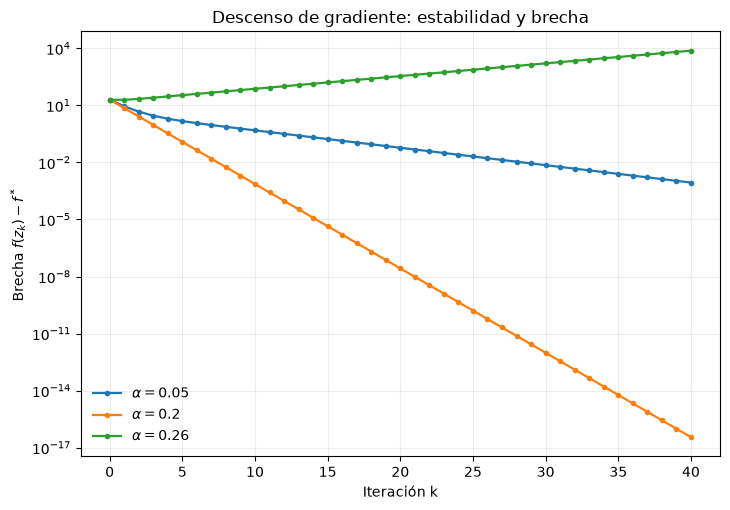

Figura generada: III4_trayectorias_curvas_nivel.png


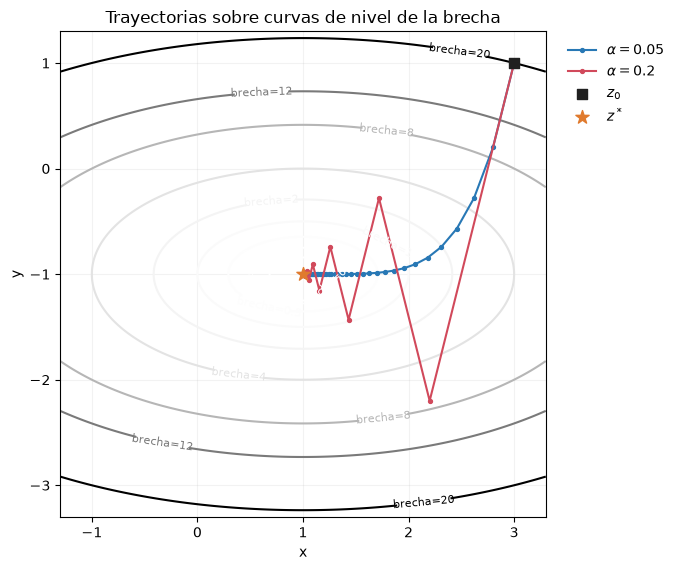

La brecha se grafica con piso 1e-16 solo en las iteraciones cuyo valor numérico es exactamente cero.


In [ ]:
fig, ax = plt.subplots(figsize=(7.4, 5.2))
for alpha_value, (_, _, gaps) in trajectories.items():
    plotted_gaps = gaps.copy()
    plotted_gaps[plotted_gaps == 0] = 1e-16
    ax.semilogy(np.arange(len(gaps)), plotted_gaps, marker="o", markersize=3, linewidth=1.6, label=fr"$\alpha={alpha_value}$")
ax.set(xlabel="Iteración k", ylabel=r"Brecha $f(z_k)-f^*$", title="Descenso de gradiente: estabilidad y brecha")
ax.grid(True, which="both", alpha=0.22)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "III4_brecha_semilog.png")
plt.show()
plt.close(fig)

contour_x = np.linspace(-1.3, 3.3, 300)
contour_y = np.linspace(-3.3, 1.3, 300)
XX, YY = np.meshgrid(contour_x, contour_y)
GAP_grid = (XX - 1) ** 2 + 4 * (YY + 1) ** 2
contour_levels = [0.1, 0.25, 0.5, 1, 2, 4, 8, 12, 20]
fig, ax = plt.subplots(figsize=(8.4, 5.8))
contours = ax.contour(XX, YY, GAP_grid, levels=contour_levels, cmap="Greys")
ax.clabel(contours, inline=True, fontsize=8, fmt=lambda level: f"brecha={level:g}")
for alpha_value, color in ((0.05, "#2878B5"), (0.20, "#D1495B")):
    points = trajectories[alpha_value][0]
    ax.plot(points[:, 0], points[:, 1], marker="o", markersize=2.8, linewidth=1.5, color=color, label=fr"$\alpha={alpha_value}$")
ax.scatter(*z0, marker="s", color="#202020", s=42, zorder=5, label="$z_0$")
ax.scatter(*z_star, marker="*", color="#E07A2D", s=100, zorder=6, label="$z^*$")
ax.set(xlabel="x", ylabel="y", title="Trayectorias sobre curvas de nivel de la brecha")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
ax.grid(alpha=0.16)
fig.tight_layout(rect=(0, 0, 0.76, 1))
save_figure(fig, "III4_trayectorias_curvas_nivel.png")
plt.show()
plt.close(fig)

print("La brecha se grafica con piso 1e-16 solo en las iteraciones cuyo valor numérico es exactamente cero.")

## Parte IV. Optimización con restricciones y programación lineal

### IV.A Multiplicadores de Lagrange

#### IV.A.1 Mínimo restringido

Minimizamos $C(x,y)=x^2+2y^2$ bajo $x+y=6$ con $\mathcal{L}=C-\lambda(x+y-6)$. Las condiciones de estacionariedad determinan $(x^*,y^*)=(4,2)$, $\lambda^*=8$ y $C^*=24$. Como la Hessiana de $C$ es definida positiva y la restricción es afín, se trata del mínimo global único.

#### IV.A.2 Sensibilidad del valor óptimo

Para $x+y=b$, las condiciones dan $x=2b/3$, $y=b/3$ y $V(b)=2b^2/3$, por lo que $V'(b)=4b/3$. Al pasar de $b=6$ a $b=6.1$, $\lambda^*=V'(6)=8$ estima $V(6.1)\approx24.8$; el valor exacto es $3721/150\approx24.8067$.

#### IV.A.3 Comprobación por sustitución

Al sustituir $x=6-y$, el costo queda $3y^2-12y+36$ y su mínimo ocurre en $y=2$.

### IV.B Programación lineal

#### IV.B.1 Formulación

Maximizamos $z=3x+2y$ sujeto a $x+y\leq4$, $x\leq2$, $y\leq3$, $x\geq0$ y $y\geq0$. Objetivo y restricciones son lineales, así que es un problema de programación lineal.

#### IV.B.2 Vértices factibles

Las intersecciones factibles son $(0,0)$, $(2,0)$, $(2,2)$, $(1,3)$ y $(0,3)$. Al evaluar $z=3x+2y$, obtenemos $0$, $6$, $10$, $9$ y $6$, respectivamente. El máximo único es $z^*=10$ en $(2,2)$; los valores se muestran en la tabla de la celda siguiente.

#### IV.B.3 Justificación

La región factible es un poliedro acotado y una función lineal alcanza un óptimo en un vértice. La evaluación confirma que $(2,2)$ es el único vértice óptimo.

In [ ]:
x_l, y_l, lam_l, b_l = sp.symbols("x_l y_l lambda_l b_l", real=True)
C_l = x_l**2 + 2 * y_l**2
lagrangian = C_l - lam_l * (x_l + y_l - 6)
stationarity = [sp.diff(lagrangian, variable) for variable in (x_l, y_l, lam_l)]
lagrange_solution = sp.solve(stationarity, (x_l, y_l, lam_l), dict=True)[0]

value_function = sp.Rational(2, 3) * b_l**2
value_slope = sp.diff(value_function, b_l)
value_at_6 = value_function.subs(b_l, 6)
value_at_61 = value_function.subs(b_l, sp.Rational(61, 10))
linear_estimate_61 = value_at_6 + value_slope.subs(b_l, 6) * sp.Rational(1, 10)
substituted_cost = sp.expand(C_l.subs(x_l, 6 - y_l))
substitution_minimizer = sp.solve(sp.diff(substituted_cost, y_l), y_l)[0]

assert lagrange_solution == {x_l: 4, y_l: 2, lam_l: 8}
assert value_at_6 == 24 and value_slope.subs(b_l, 6) == 8
assert value_at_61 == sp.Rational(3721, 150)
assert linear_estimate_61 == sp.Rational(124, 5)
assert substitution_minimizer == 2

print("Condiciones:", stationarity)
print("Solución:", lagrange_solution, "; costo mínimo:", C_l.subs(lagrange_solution))
print("V(b)=", value_function, "; V'(b)=", value_slope)
print(f"Para b=6.1: exacto={value_at_61}, estimación lineal={linear_estimate_61}")
print("Sustitución x=6-y:", substituted_cost, "; y óptima:", substitution_minimizer)
lagrange_value_table = results_table([("V(6.1) exacto", float(value_at_61)), ("Estimación lineal", float(linear_estimate_61))], ["Cantidad", "Valor"])

Condiciones: [-lambda_l + 2*x_l, -lambda_l + 4*y_l, -x_l - y_l + 6]
Solución: {lambda_l: 8, x_l: 4, y_l: 2} ; costo mínimo: 24
V(b)= 2*b_l**2/3 ; V'(b)= 4*b_l/3
Para b=6.1: exacto=3721/150, estimación lineal=124/5
Sustitución x=6-y: 3*y_l**2 - 12*y_l + 36 ; y óptima: 2


,Cantidad,Valor
0,V(6.1) exacto,24.80666667
1,Estimación lineal,24.80000000


,Cantidad,Valor
0,V(6.1) exacto,24.80666667
1,Estimación lineal,24.80000000


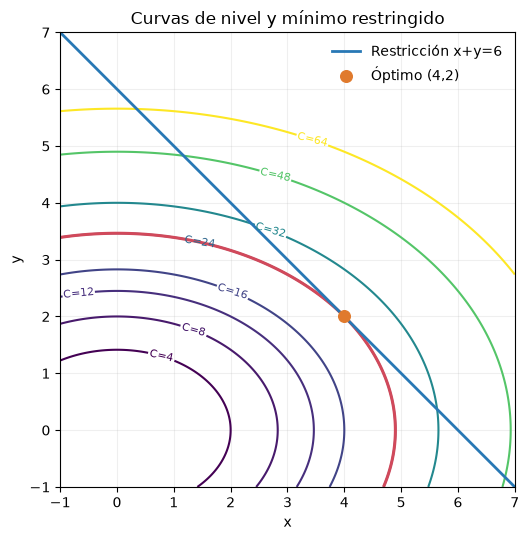

In [ ]:
x_plot = np.linspace(-1, 7, 320)
y_plot = np.linspace(-1, 7, 320)
X_lagrange, Y_lagrange = np.meshgrid(x_plot, y_plot)
C_grid = X_lagrange**2 + 2 * Y_lagrange**2
constraint_x = np.linspace(-1, 7, 300)
constraint_y = 6 - constraint_x

fig, ax = plt.subplots(figsize=(7.4, 5.5))
contours = ax.contour(X_lagrange, Y_lagrange, C_grid, levels=[4, 8, 12, 16, 24, 32, 48, 64], cmap="viridis")
ax.clabel(contours, inline=True, fontsize=8, fmt="C=%.0f")
ax.contour(X_lagrange, Y_lagrange, C_grid, levels=[24], colors="#D1495B", linewidths=2.2)
ax.plot(constraint_x, constraint_y, color="#2878B5", linewidth=2, label="Restricción x+y=6")
ax.scatter(4, 2, color="#E07A2D", s=70, zorder=5, label="Óptimo (4,2)")
ax.set(xlabel="x", ylabel="y", title="Curvas de nivel y mínimo restringido")
ax.set_xlim(-1, 7)
ax.set_ylim(-1, 7)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "IV_A_lagrange.png")
plt.show()
plt.close(fig)

,x,y,z=3x+2y
0,-0.0,-0.0,-0.0
1,-0.0,3.0,6.0
2,1.0,3.0,9.0
3,2.0,-0.0,6.0
4,2.0,2.0,10.0


Vértices factibles: [(np.float64(-0.0), np.float64(-0.0)), (np.float64(-0.0), np.float64(3.0)), (np.float64(1.0), np.float64(3.0)), (np.float64(2.0), np.float64(-0.0)), (np.float64(2.0), np.float64(2.0))]
Óptimo único: (np.float64(2.0), np.float64(2.0)) con z*= 10.0


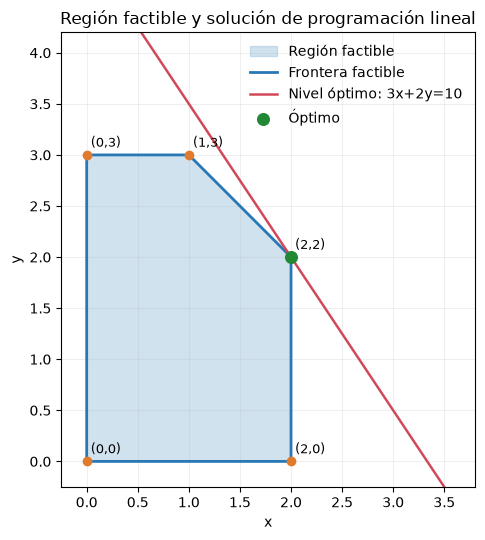

In [ ]:
from itertools import combinations

constraint_matrix = np.array([[1, 1], [1, 0], [0, 1], [-1, 0], [0, -1]], dtype=float)
constraint_bounds = np.array([4, 2, 3, 0, 0], dtype=float)
vertices = set()
for row_indices in combinations(range(len(constraint_matrix)), 2):
    active_matrix = constraint_matrix[list(row_indices)]
    if abs(np.linalg.det(active_matrix)) < 1e-12:
        continue
    candidate = np.linalg.solve(active_matrix, constraint_bounds[list(row_indices)])
    if np.all(constraint_matrix @ candidate <= constraint_bounds + 1e-10):
        vertices.add(tuple(np.round(candidate, 12)))

vertices = sorted(vertices)
vertex_values = [(x_value, y_value, 3 * x_value + 2 * y_value) for x_value, y_value in vertices]
optimal_value = max(row[2] for row in vertex_values)
optimal_vertices = [(row[0], row[1]) for row in vertex_values if np.isclose(row[2], optimal_value)]
assert vertices == [(0.0, 0.0), (0.0, 3.0), (1.0, 3.0), (2.0, 0.0), (2.0, 2.0)]
assert optimal_vertices == [(2.0, 2.0)] and optimal_value == 10

results_table(vertex_values, ["x", "y", "z=3x+2y"])
print("Vértices factibles:", vertices)
print("Óptimo único:", optimal_vertices[0], "con z*=", optimal_value)

polygon = np.array([(0, 0), (2, 0), (2, 2), (1, 3), (0, 3)])
fig, ax = plt.subplots(figsize=(7.4, 5.5))
ax.fill(polygon[:, 0], polygon[:, 1], color="#8DB7D8", alpha=0.4, label="Región factible")
closed_polygon = np.vstack([polygon, polygon[0]])
ax.plot(closed_polygon[:, 0], closed_polygon[:, 1], color="#2878B5", linewidth=2, label="Frontera factible")
for vertex in polygon:
    ax.scatter(*vertex, color="#E07A2D", zorder=5)
    ax.annotate(f"({vertex[0]:g},{vertex[1]:g})", vertex + [0.04, 0.08], fontsize=9)
level_x = np.linspace(-0.2, 3.7, 200)
ax.plot(level_x, (10 - 3 * level_x) / 2, color="#D1495B", linewidth=1.8, label="Nivel óptimo: 3x+2y=10")
ax.scatter(2, 2, color="#228833", s=70, zorder=6, label="Óptimo")
ax.set(xlabel="x", ylabel="y", title="Región factible y solución de programación lineal")
ax.set_xlim(-0.25, 3.8)
ax.set_ylim(-0.25, 4.2)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
save_figure(fig, "IV_B_programacion_lineal.png")
plt.show()
plt.close(fig)

## Parte V. Análisis numérico y regularización

### V.A Truncamiento, redondeo y orden de convergencia

#### V.A.1 Desarrollos de Taylor

Para $g(x)=\ln(1+x)$, desarrollamos alrededor de $x=1$:
\[
g(1+h)=\ln 2+\frac{h}{2}-\frac{h^2}{8}+\frac{h^3}{24}-\frac{h^4}{64}+O(h^5),
\]
\[
g(1-h)=\ln 2-\frac{h}{2}-\frac{h^2}{8}-\frac{h^3}{24}-\frac{h^4}{64}+O(h^5).
\]
En la diferencia hacia adelante, $(g(1+h)-g(1))/h=1/2-h/8+h^2/24+O(h^3)$, de modo que el error principal es $-h/8$ y el orden es $O(h)$. En la diferencia central se restan las dos expansiones: se cancelan los términos pares y, al dividir por $2h$, queda $1/2+h^2/24+O(h^4)$. Su error principal es $h^2/24$ y el orden es $O(h^2)$.

#### V.A.2 Aproximaciones numéricas en `float64`

La tabla de la celda siguiente se calcula con `np.log1p`, igual que los valores reportados en el documento. La diferencia hacia adelante mantiene orden empírico cercano a uno hasta $h\approx10^{-6}$; la central muestra orden cercano a dos hasta $h\approx10^{-4}$. Para pasos menores domina la cancelación en doble precisión.

#### V.A.3 Error y redondeo

La gráfica compara los errores con referencias proporcionales a $h$ y $h^2$. Reducir $h$ disminuye primero el error de truncamiento; para pasos muy pequeños se restan valores casi iguales, se pierden cifras significativas y el error deja de mejorar.

### V.B Condicionamiento y efecto de Ridge

#### V.B.1 Solución simbólica y número de condición

Para $A_\varepsilon=\begin{pmatrix}1&1\\1&1+\varepsilon\end{pmatrix}$, $b=(2,2+\varepsilon)^T$ y $\delta b=(0,10^{-6})^T$, restar la primera ecuación de la segunda da $\varepsilon x_2=\varepsilon$ en el sistema original y $\varepsilon x_2=\varepsilon+\delta$ en el perturbado. Por tanto,
\[
x=(1,1)^T,\qquad x_\delta=(1-\delta/\varepsilon,1+\delta/\varepsilon)^T.
\]
Los autovalores son $1+\varepsilon/2\pm\sqrt{4+\varepsilon^2}/2$, aproximadamente $2$ y $\varepsilon/2$ si $\varepsilon$ es pequeño. Así, $\kappa_2(A_\varepsilon)\approx4/\varepsilon=4\times10^8$.

#### V.B.2 Cálculo numérico de la sensibilidad

Con $\varepsilon=10^{-8}$ y $\delta=10^{-6}$, NumPy da $x_\delta\approx(-99.000001,101.000001)^T$. La norma del vector del enunciado es
\[
\|b\|_2=\sqrt{2^2+(2+10^{-8})^2}\approx2.82842713.
\]
La perturbación relativa es $\|\delta b\|_2/\|b\|_2\approx3.535534\times10^{-7}$; el cambio relativo de la solución es del orden de $10^2$, con amplificación aproximada de $2.828427\times10^8$. Esto refleja el mal condicionamiento, no un fallo de `np.linalg.solve`.

#### V.B.3 Regularización con Ridge

Al resolver $(A_\varepsilon+\lambda I)x_R=b$ con $\lambda=0.01$, el número de condición baja a cerca de $201$. Las soluciones son $x_R\approx(0.99502487,0.99502488)^T$ y $x_{R,\delta}\approx(0.99497512,0.99507513)^T$; el cambio relativo disminuye a cerca de $5.03\times10^{-5}$. La distancia $\|x_R-x\|_2\approx0.00704$ cuantifica el sesgo.

#### V.B.4 Relación con la regresión Ridge

Si $X^TX$ tiene autovalores pequeños o nulos por colinealidad, sumar $\lambda I$ los desplaza de $\mu_i$ a $\mu_i+\lambda$. En $w_R=(X^TX+\lambda I)^{-1}X^Ty$, esto reduce la sensibilidad de los coeficientes. El compromiso es sesgo-estabilidad: una mayor regularización estabiliza la solución, pero la aleja de la no regularizada.

,k,h,D_h+,D_h0,E+,E0,p+,p0
0,1,0.10000000,0.48790164,0.50041729,1.20983583e-02,4.17292785e-04,NaN,NaN
1,2,0.01000000,0.49875415,0.50000417,1.24584890e-03,4.16672917e-06,0.98726107,2.00064560
2,3,0.00100000,0.49987504,0.50000004,1.24958349e-04,4.16666706e-08,0.99870009,2.00000647
3,4,0.00010000,0.49998750,0.50000000,1.24995836e-05,4.16278567e-10,0.99986973,2.00040475
4,5,0.00001000,0.49999875,0.50000000,1.24998573e-06,8.82671713e-12,0.99999049,1.67358484
5,6,0.00000100,0.49999987,0.50000000,1.25052246e-07,4.11333190e-11,0.99981356,-0.66839454
6,7,0.00000010,0.49999999,0.50000000,1.19205197e-08,2.91933588e-10,1.02079631,-0.85109031
7,8,0.00000001,0.50000000,0.50000000,3.03873549e-09,3.03873549e-09,0.59360229,-1.01740883


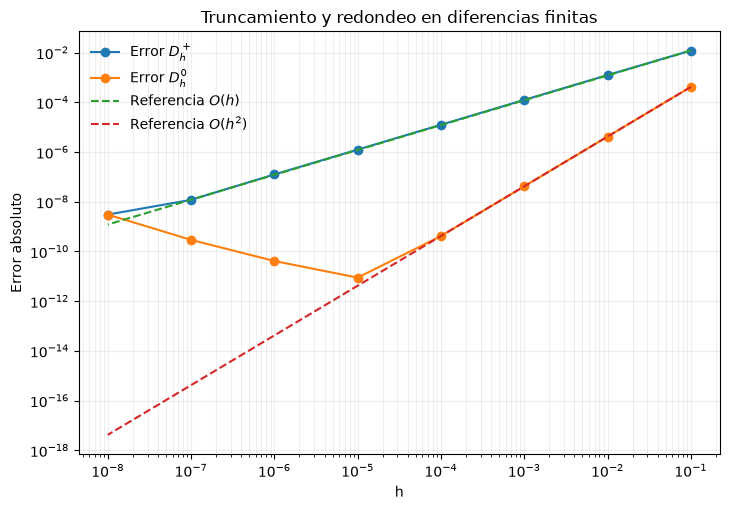

El orden central deja de seguir h^2 para h pequeño por redondeo y cancelación.


In [ ]:
x_values_finite = np.logspace(-1, -8, 8, dtype=np.float64)
g_values = lambda value: np.log1p(value)
forward_values = (g_values(1 + x_values_finite) - g_values(1.0)) / x_values_finite
central_values = (g_values(1 + x_values_finite) - g_values(1 - x_values_finite)) / (2 * x_values_finite)
forward_errors = np.abs(forward_values - 0.5)
central_errors = np.abs(central_values - 0.5)
forward_orders = np.full(8, np.nan)
central_orders = np.full(8, np.nan)
forward_orders[1:] = np.log10(forward_errors[:-1] / forward_errors[1:])
central_orders[1:] = np.log10(central_errors[:-1] / central_errors[1:])

finite_difference_table = results_table(
    [(index + 1, h, forward_values[index], central_values[index], forward_errors[index], central_errors[index], forward_orders[index], central_orders[index]) for index, h in enumerate(x_values_finite)],
    ["k", "h", "D_h+", "D_h0", "E+", "E0", "p+", "p0"]
)
assert np.isclose(forward_orders[2], 0.999, atol=0.01)
assert np.isclose(central_orders[2], 2.0, atol=0.01)

reference_h = x_values_finite
forward_reference = forward_errors[0] * reference_h / reference_h[0]
central_reference = central_errors[0] * (reference_h / reference_h[0]) ** 2
fig, ax = plt.subplots(figsize=(7.4, 5.2))
ax.loglog(x_values_finite, forward_errors, marker="o", label=r"Error $D_h^+$")
ax.loglog(x_values_finite, central_errors, marker="o", label=r"Error $D_h^0$")
ax.loglog(reference_h, forward_reference, linestyle="--", label=r"Referencia $O(h)$")
ax.loglog(reference_h, central_reference, linestyle="--", label=r"Referencia $O(h^2)$")
ax.set(xlabel="h", ylabel="Error absoluto", title="Truncamiento y redondeo en diferencias finitas")
ax.grid(True, which="both", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "V_A_errores_diferencias_finitas.png")
plt.show()
plt.close(fig)
print("El orden central deja de seguir h^2 para h pequeño por redondeo y cancelación.")

In [ ]:
epsilon_sym, delta_sym = sp.symbols("epsilon delta", positive=True)
A_sym = sp.Matrix([[1, 1], [1, 1 + epsilon_sym]])
b_sym = sp.Matrix([2, 2 + epsilon_sym])
db_sym = sp.Matrix([0, delta_sym])
x_symbolic = A_sym.LUsolve(b_sym)
x_perturbed_symbolic = A_sym.LUsolve(b_sym + db_sym)
lambda_eigenvalues = [(2 + epsilon_sym + sign * sp.sqrt(4 + epsilon_sym**2)) / 2 for sign in (-1, 1)]

EPSILON = 1e-8
DELTA_B = np.array([0.0, 1e-6])
A_numeric = np.array([[1.0, 1.0], [1.0, 1.0 + EPSILON]], dtype=np.float64)
b_numeric = np.array([2.0, 2.0 + EPSILON], dtype=np.float64)
x_numeric = np.linalg.solve(A_numeric, b_numeric)
x_delta = np.linalg.solve(A_numeric, b_numeric + DELTA_B)
condition_unregularized = np.linalg.cond(A_numeric, 2)
relative_b_perturbation = np.linalg.norm(DELTA_B) / np.linalg.norm(b_numeric)
relative_x_change = np.linalg.norm(x_delta - x_numeric) / np.linalg.norm(x_numeric)
amplification_unregularized = relative_x_change / relative_b_perturbation

LAMBDA_RIDGE = 0.01
A_ridge = A_numeric + LAMBDA_RIDGE * np.eye(2)
x_ridge = np.linalg.solve(A_ridge, b_numeric)
x_ridge_delta = np.linalg.solve(A_ridge, b_numeric + DELTA_B)
condition_ridge = np.linalg.cond(A_ridge, 2)
relative_ridge_change = np.linalg.norm(x_ridge_delta - x_ridge) / np.linalg.norm(x_ridge)
amplification_ridge = relative_ridge_change / relative_b_perturbation
ridge_bias = np.linalg.norm(x_ridge - x_numeric)

assert sp.simplify(x_numeric[0] - 1.0) < 1e-7
assert np.isclose(condition_unregularized, 4e8, rtol=2e-2)
assert np.isclose(condition_ridge, 201.0, rtol=1e-3)
assert np.allclose(x_ridge, [0.99502487, 0.99502488], atol=1e-7)
assert np.allclose(x_ridge_delta, [0.99497512, 0.99507513], atol=1e-7)

print("Solución simbólica original:", x_symbolic)
print("Solución simbólica perturbada:", x_perturbed_symbolic)
print("Autovalores simbólicos:", lambda_eigenvalues)
conditioning_table = results_table(
    [
        ("Sin Ridge", condition_unregularized, *x_numeric, *x_delta, relative_b_perturbation, relative_x_change, amplification_unregularized, 0.0),
        ("Ridge lambda=0.01", condition_ridge, *x_ridge, *x_ridge_delta, relative_b_perturbation, relative_ridge_change, amplification_ridge, ridge_bias),
    ],
    ["Caso", "kappa2", "x1", "x2", "x1 perturbada", "x2 perturbada", "||db||/||b||", "||dx||/||x||", "Amplificación", "Sesgo ||xR-x||"]
)

Solución simbólica original: Matrix([[1], [1]])
Solución simbólica perturbada: Matrix([[2 - (delta + epsilon)/epsilon], [(delta + epsilon)/epsilon]])
Autovalores simbólicos: [epsilon/2 - sqrt(epsilon**2 + 4)/2 + 1, epsilon/2 + sqrt(epsilon**2 + 4)/2 + 1]


,Caso,kappa2,x1,x2,x1 perturbada,x2 perturbada,||db||/||b||,||dx||/||x||,Amplificación,Sesgo ||xR-x||
0,Sin Ridge,4.00000000e+08,1.00000000,1.00000000,-99.00000062,101.00000062,0.00000035,100.00000062,2.82842715e+08,0.00000000
1,Ridge lambda=0.01,2.00999900e+02,0.99502487,0.99502488,0.99497512,0.99507513,0.00000035,0.00005025,1.42130151e+02,0.00703589


## Parte VI. Descenso batch y minibatch SGD

### VI.1 Pérdida y mínimo global

Con los datos $x=(-1,0,1,2)$ y $y=(-2,0,2,4)$ se cumple $y_i=2x_i$. Por tanto,
\[
L(w)=\frac14\sum_{i=1}^4(wx_i-y_i)^2=\frac32(w-2)^2=\frac32w^2-6w+6,
\qquad L'(w)=3w-6.
\]
El mínimo global es $w^*=2$ y $L(w^*)=0$.

### VI.2 Dos actualizaciones batch a mano

Desde $w_0=0$ con $\alpha=0.1$, y usando $L'(w)=3w-6$,
\[
\begin{aligned}
w_1&=w_0-\alpha L'(w_0)=0-0.1(-6)=0.6,\\
w_2&=w_1-\alpha L'(w_1)=0.6-0.1(-4.2)=1.02.
\end{aligned}
\]
Las pérdidas son $L(w_0)=6$, $L(w_1)=2.94$ y $L(w_2)=1.4406$.

| $k$ | $w_k$ | $L'(w_k)$ | $L(w_k)$ |
|---:|---:|---:|---:|
| 0 | 0.0000 | -6.0000 | 6.0000 |
| 1 | 0.6000 | -4.2000 | 2.9400 |
| 2 | 1.0200 | -2.9400 | 1.4406 |

### VI.3 Entrenamiento durante 30 épocas

Batch realiza una actualización por época; minibatch de tamaño dos realiza dos actualizaciones, con una nueva permutación por época. En ambos casos se procesan los cuatro ejemplos por época. Para minibatch se reportan cinco semillas y la gráfica muestra la pérdida completa tras cada época.

### VI.4 Variabilidad y costo por época

Si el minibatch se elige uniformemente, el promedio de sus gradientes es insesgado para el gradiente de la pérdida completa. Una actualización puede reducir la pérdida del lote y aumentar temporalmente la pérdida total; reducir $\alpha$ puede atenuar esas fluctuaciones. En este experimento, batch procesa los cuatro datos en una actualización y minibatch procesa dos datos en cada una de dos actualizaciones: el total por época es el mismo, pero cambia el número de actualizaciones. Adam suaviza y adapta los pasos mediante promedios móviles del gradiente y de su cuadrado.

In [ ]:
x_data = np.array([-1.0, 0.0, 1.0, 2.0])
y_data = np.array([-2.0, 0.0, 2.0, 4.0])


def regression_loss(weight, features=x_data, targets=y_data):
    return np.mean((weight * features - targets) ** 2)


def regression_gradient(weight, features=x_data, targets=y_data):
    return 2 * np.mean(features * (weight * features - targets))


assert np.isclose(regression_loss(0.0), 6.0)
assert np.isclose(regression_gradient(0.0), -6.0)

batch_weight = 0.0
batch_history = [regression_loss(batch_weight)]
batch_steps = []
for _ in range(2):
    gradient_value = regression_gradient(batch_weight)
    batch_steps.append((batch_weight, gradient_value, regression_loss(batch_weight)))
    batch_weight -= 0.1 * gradient_value
    batch_history.append(regression_loss(batch_weight))
assert_close([batch_weight], [1.02])
assert_close(batch_history, [6.0, 2.94, 1.4406])


def train_batch(epochs=30, learning_rate=0.1):
    weight = 0.0
    history = [regression_loss(weight)]
    for _ in range(epochs):
        weight -= learning_rate * regression_gradient(weight)
        history.append(regression_loss(weight))
    return weight, history


def train_minibatch(seed, epochs=30, learning_rate=0.1, batch_size=2):
    generator = np.random.default_rng(seed)
    weight = 0.0
    history = [regression_loss(weight)]
    for _ in range(epochs):
        permutation = generator.permutation(len(x_data))
        for start in range(0, len(x_data), batch_size):
            indices = permutation[start:start + batch_size]
            weight -= learning_rate * regression_gradient(weight, x_data[indices], y_data[indices])
        history.append(regression_loss(weight))
    return weight, history


batch_final_weight, batch_loss_history = train_batch()
minibatch_runs = {seed: train_minibatch(seed) for seed in range(5)}
training_rows = [("GD batch", "-", batch_final_weight, batch_loss_history[-1])]
training_rows.extend(("Minibatch SGD", seed, result[0], result[1][-1]) for seed, result in minibatch_runs.items())
training_table = results_table(training_rows, ["Método", "Semilla", "w final", "L(w) final"])
assert abs(batch_final_weight - 2.0) < 1e-4
assert all(abs(result[0] - 2.0) < 1e-6 for result in minibatch_runs.values())
print("Dos pasos batch:", batch_steps, "; w2=", batch_weight, "; pérdidas=", batch_history)

,Método,Semilla,w final,L(w) final
0,GD batch,-,1.99995492,3.04813116e-09
1,Minibatch SGD,0,2.00000000,3.86842502e-20
2,Minibatch SGD,1,2.00000000,2.98826250e-20
3,Minibatch SGD,2,2.00000000,5.00782272e-20
4,Minibatch SGD,3,2.00000000,3.86842502e-20
5,Minibatch SGD,4,2.00000000,2.98826250e-20


Dos pasos batch: [(0.0, np.float64(-6.0), np.float64(6.0)), (np.float64(0.6000000000000001), np.float64(-4.199999999999999), np.float64(2.9399999999999995))] ; w2= 1.02 ; pérdidas= [np.float64(6.0), np.float64(2.9399999999999995), np.float64(1.4405999999999999)]


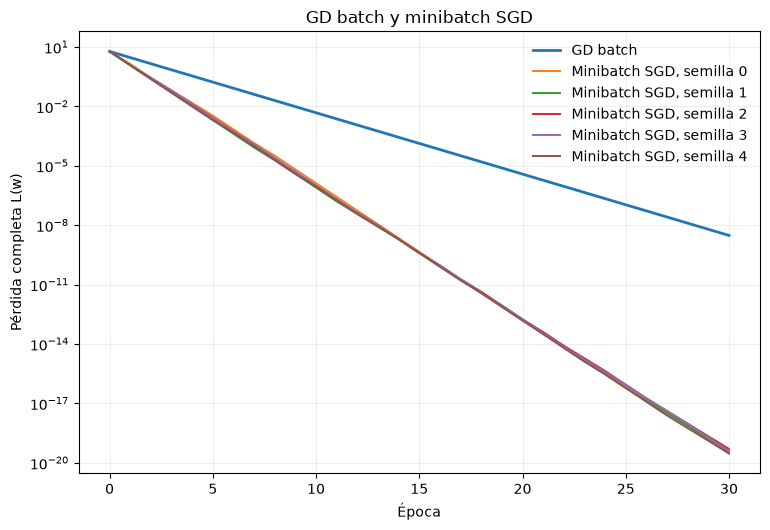

El piso numérico solo se aplica a pérdidas exactamente nulas para dibujarlas en escala logarítmica.


In [ ]:
fig, ax = plt.subplots(figsize=(7.8, 5.4))
batch_plot = np.asarray(batch_loss_history, dtype=float)
batch_plot[batch_plot == 0] = np.finfo(float).tiny
ax.semilogy(np.arange(len(batch_plot)), batch_plot, linewidth=2, label="GD batch")
for seed, (_, history) in minibatch_runs.items():
    loss_values = np.asarray(history, dtype=float)
    loss_values[loss_values == 0] = np.finfo(float).tiny
    ax.semilogy(np.arange(len(loss_values)), loss_values, linewidth=1.4, label=f"Minibatch SGD, semilla {seed}")
ax.set(xlabel="Época", ylabel="Pérdida completa L(w)", title="GD batch y minibatch SGD")
ax.grid(True, which="both", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "VI3_batch_minibatch.png")
plt.show()
plt.close(fig)
print("El piso numérico solo se aplica a pérdidas exactamente nulas para dibujarlas en escala logarítmica.")